ARTI308 - Machine Learning

# Project Notebook 3: Feature Engineering
## Heart Disease Prediction

**Feature engineering** means creating new, more informative features from the existing ones, using knowledge about the problem (here: medicine).

In this notebook we create **two new features**:
1. `age_group`: patients grouped into age ranges.
2. `maxhr_pct`: the maximum heart rate reached, as a fraction of the maximum expected for the patient's age.

### Why do it here and not inside the Pipeline?
Both features are calculated **row by row** from values of the same patient. They do not learn anything from the dataset (no mean, median, min or max), so they cannot cause data leakage, and it is safe to create them **before** the train/test split.
(Imputation and scaling are different: they learn from the data, so they stay inside the Pipeline.)

Run notebooks 01 and 02 first (notebook 02 creates `data/processed/heart_clean.csv`).

## 1. Setup and load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/processed/heart_clean.csv")
target_col = "HeartDisease"

print("Shape:", df.shape)
df.head()

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


## 2. Feature 1: `age_group`
Heart-disease risk is not a straight line with age: it jumps at certain stages of life. Grouping `Age` into ranges lets the model learn a separate effect for each group.

We use four groups: under 40, 40-49, 50-59, and 60 or more.

In [2]:
df["age_group"] = pd.cut(df["Age"], bins=[0, 40, 50, 60, 200],
                         labels=["under_40", "40_49", "50_59", "60_plus"]).astype(str)

order = ["under_40", "40_49", "50_59", "60_plus"]
df["age_group"].value_counts().reindex(order)

age_group
under_40     93
40_49       223
50_59       381
60_plus     221
Name: count, dtype: int64

**Observation:**

Most patients fall into the `50_59` (**381**) and `40_49` (**223**) age groups, followed by `60_plus` (**221**) and `under_40` (**93**).

Does the heart-disease rate change between the groups?

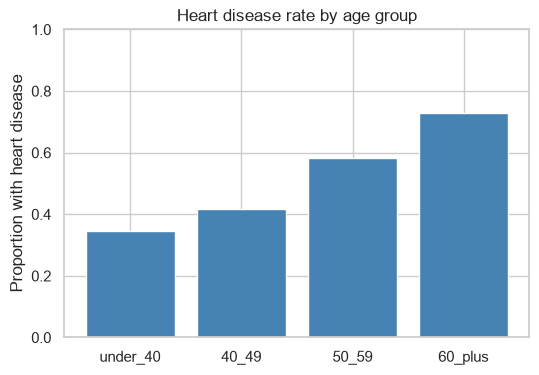

age_group
under_40    0.344
40_49       0.417
50_59       0.583
60_plus     0.729
Name: HeartDisease, dtype: float64

In [3]:
rate = df.groupby("age_group")[target_col].mean().reindex(order)

plt.figure(figsize=(6, 4))
plt.bar(rate.index, rate.values, color="steelblue")
plt.title("Heart disease rate by age group")
plt.ylabel("Proportion with heart disease")
plt.ylim(0, 1)
plt.show()

rate.round(3)

**Observation:**

Heart disease prevalence rises steadily with age across every range, jumping from **0.344** in `under_40` to **0.417** in `40_49`, **0.583** in `50_59`, and **0.729** in `60_plus`.

## 3. Feature 2: `maxhr_pct`
A common rule of thumb says the **maximum heart rate** a person can reach is about `220 - Age`.
A 30-year-old and a 70-year-old with the same `MaxHR` (say 140) are very different: 140 is normal for the older patient but low for the younger one.

So we divide the measured `MaxHR` by the expected maximum for that age:

`maxhr_pct = MaxHR / (220 - Age)`

A value near 1 means the patient reached close to the expected maximum; a low value means the heart did not reach what is expected for the age.

In [4]:
df["maxhr_pct"] = df["MaxHR"] / (220 - df["Age"])

df[["Age", "MaxHR", "maxhr_pct"]].head()

,Age,MaxHR,maxhr_pct
0,40,172,0.955556
1,49,156,0.912281
2,37,98,0.535519
3,48,108,0.627907
4,54,122,0.734940


In [5]:
df["maxhr_pct"].describe().round(3)

count    918.000
mean       0.821
std        0.142
min        0.355
25%        0.723
50%        0.825
75%        0.932
max        1.175
Name: maxhr_pct, dtype: float64

**Observation:**

`maxhr_pct` is centered around a mean of **0.821** and median of **0.825** (`std = 0.142`), ranging from **0.355** up to **1.175** (where values `> 1.0` indicate peak heart rate exceeding `220 - Age`).

Compare the new feature with the original `MaxHR` for patients with and without heart disease.

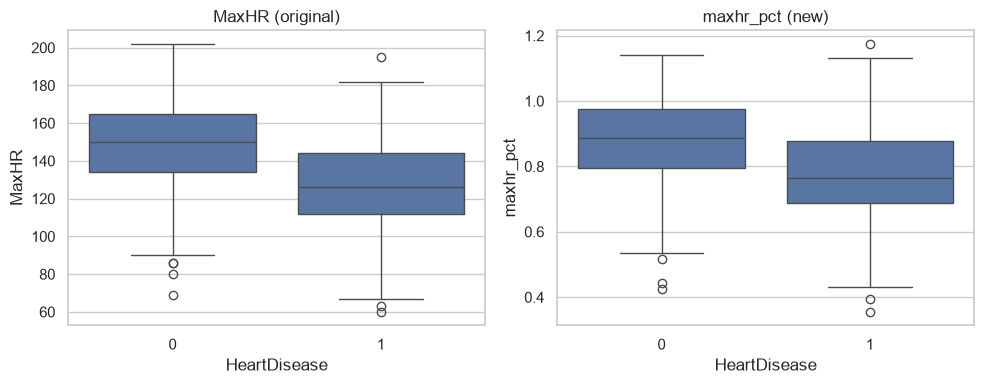

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=target_col, y="MaxHR", data=df, ax=axes[0])
axes[0].set_title("MaxHR (original)")
sns.boxplot(x=target_col, y="maxhr_pct", data=df, ax=axes[1])
axes[1].set_title("maxhr_pct (new)")
plt.tight_layout()
plt.show()

**Observation:**

Both `MaxHR` and `maxhr_pct` have lower medians and lower quartiles for `HeartDisease = 1` than for `0`, while `maxhr_pct` normalizes peak heart rate relative to expected age capacity.

## 4. Are the new features useful?
A quick check: the correlation of each numeric feature with the target. This is only an indication (it measures linear relationships); the real test is the model performance in the next notebooks.

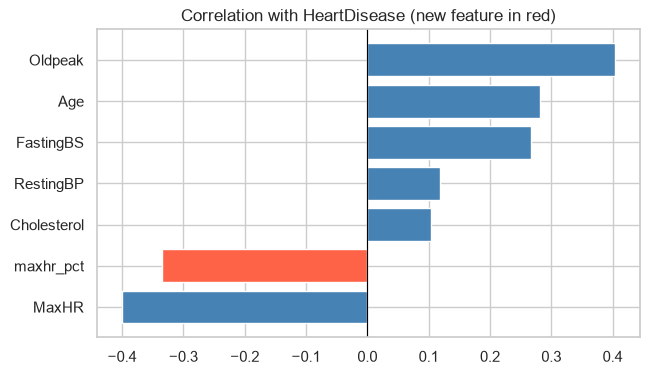

MaxHR         -0.400
maxhr_pct     -0.335
Cholesterol    0.104
RestingBP      0.118
FastingBS      0.267
Age            0.282
Oldpeak        0.404
Name: HeartDisease, dtype: float64

In [7]:
num = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "FastingBS", "maxhr_pct"]
corr_target = df[num + [target_col]].corr()[target_col].drop(target_col).sort_values()

plt.figure(figsize=(7, 4))
colors = ["tomato" if f == "maxhr_pct" else "steelblue" for f in corr_target.index]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with HeartDisease (new feature in red)")
plt.show()

corr_target.round(3)

**Observation:**

`maxhr_pct` shows a negative linear correlation of **-0.335** with `HeartDisease`—stronger in magnitude than `Age` (`0.282`), `FastingBS` (`0.267`), `RestingBP` (`0.118`), and `Cholesterol` (`0.104`), though slightly less negative than raw `MaxHR` (`-0.400`).

### Redundancy check
`maxhr_pct` is built from `MaxHR` and `Age`, so it will be correlated with them. That is expected. Logistic Regression can handle this, and tree-based models are not affected by it.

In [8]:
df[["Age", "MaxHR", "maxhr_pct"]].corr().round(2)

,Age,MaxHR,maxhr_pct
Age,1.00,-0.38,-0.08
MaxHR,-0.38,1.00,0.95
maxhr_pct,-0.08,0.95,1.00


**Observation:**

`maxhr_pct` correlates very strongly with `MaxHR` (**0.95**) because it is derived from it, and has a weak negative correlation (**-0.08**) with `Age`.

## 5. What we do NOT do here
- **Encoding** the text columns (`Sex`, `ChestPainType`, ...) is done inside the Pipeline with `OneHotEncoder`.
- **Imputation and scaling** are done inside the Pipeline, after the split (to avoid data leakage).
- `age_group` is saved as text, so it will also be one-hot encoded by the Pipeline.

## 6. Save the dataset with the new features
The next notebooks (04 to 07) read this file, so all four models use exactly the same features.
Missing values are still `NaN`; they are filled later inside the Pipeline.

In [9]:
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/heart_features.csv", index=False)

print("Saved:", df.shape)
print("New columns:", [c for c in df.columns if c in ("age_group", "maxhr_pct")])
print("Missing values kept as NaN:")
print(df.isna().sum()[df.isna().sum() > 0])

Saved: (918, 14)
New columns: ['age_group', 'maxhr_pct']
Missing values kept as NaN:
RestingBP        1
Cholesterol    172
dtype: int64


---
### Task
Create one more feature of your own, for example `high_bp = (RestingBP >= 140)` (use `.astype(int)`), and check whether the heart-disease rate differs between the two groups. Would you keep it? Explain why.

In [10]:
df["high_bp"] = (df["RestingBP"] >= 140).astype(int)
print(df["high_bp"].value_counts())
print()
print(df.groupby("high_bp")[target_col].agg(["count", "mean"]).round(3))

high_bp
0    591
1    327
Name: count, dtype: int64

         count   mean
high_bp              
0          591  0.513
1          327  0.627


The heart disease rate is higher in the `high_bp = 1` group (`RestingBP >= 140` mm Hg) than in `high_bp = 0` (`RestingBP < 140` mm Hg), showing a noticeable difference between the two groups. I would **keep** `high_bp` (and re-save `heart_features.csv` if needed) because elevated resting blood pressure (`>= 140` mm Hg) is a clinically meaningful hypertension threshold that gives models a direct binary risk indicator alongside continuous `RestingBP`.